# Task 2 – Merger Arbitrage Spread
## Introduction
This study examines merger arbitrage through three completed cash acquisitions: Microsoft–Activision Blizzard, Cisco–Splunk, and IBM–HashiCorp.  The study also includes the failed Amazon–iRobot acquisition. 
## Results of Completed Mergers
Although Activision Blizzard had the highest initial deal spread, Splunk generated the highest realised annualised return because its acquisition was completed earlier than the assumed closing date. This shows that both the deal spread and the holding period are important.

The failed Amazon–iRobot acquisition: Amazon initially offered 61 USD per share in August 2022. The offer was later reduced to 51.75 USD, and the acquisition was officially cancelled in January 2024. The failed acquisition resulted in a 73.97% loss (illustrating the asymmetric payoff structure).
## Portfolio Analysis
Two portfolios were constructed with an initial capital of $10,000 each. Portfolio A includes only the three completed mergers, while Portfolio B also includes the failed acquisition as well. Capital is allocated equally across the selected deals at the beginning of the simulation.

Including one failed acquisition reduced the portfolio return by 21.05 percentage points and significantly increased maximum drawdown. Even though three out of four acquisitions were successful, Portfolio B generated a negative total return.


In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

from datetime import datetime

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Collect historical merger deal data
# Prices are obtained from historical archives and SEC filings
# Expected closing dates are approximated using period-end dates

deals = pd.DataFrame({
    "Acquirer": ["Microsoft", "Cisco", "IBM"],
    "Target": ["Activision Blizzard", "Splunk", "HashiCorp"],
    "Ticker": ["ATVI", "SPLK", "HCP"],
    "Announcement_Date": [
        "2022-01-18", "2023-09-21", "2024-04-24"
    ],
    "Entry_Date": [
        "2022-01-18", "2023-09-21", "2024-04-25"
    ],
    "Entry_Price": [82.31, 144.43, 32.82],
    "Offer_Price": [95.00, 157.00, 35.00],
    "Expected_Close": [
        "2023-06-30", "2024-09-30", "2024-12-31"
    ],
    "Actual_Close": [
        "2023-10-13", "2024-03-18", "2025-02-27"
    ],
    "Final_Cash_Payment": [95.00, 157.00, 35.00]
})

# Convert date columns to datetime format

date_columns = [
    "Announcement_Date",
    "Entry_Date",
    "Expected_Close",
    "Actual_Close"
]

for col in date_columns:
    deals[col] = pd.to_datetime(deals[col])

display(deals)

,Acquirer,Target,Ticker,Announcement_Date,Entry_Date,Entry_Price,Offer_Price,Expected_Close,Actual_Close,Final_Cash_Payment
0,Microsoft,Activision Blizzard,ATVI,2022-01-18,2022-01-18,82.31,95.0,2023-06-30,2023-10-13,95.0
1,Cisco,Splunk,SPLK,2023-09-21,2023-09-21,144.43,157.0,2024-09-30,2024-03-18,157.0
2,IBM,HashiCorp,HCP,2024-04-24,2024-04-25,32.82,35.0,2024-12-31,2025-02-27,35.0


In [5]:
# Calculate absolute and percentage deal spreads

deals["Absolute_Spread"] = (
    deals["Offer_Price"] - deals["Entry_Price"]
)

deals["Spread_Pct"] = (
    deals["Absolute_Spread"] / deals["Entry_Price"]
) * 100

# Display deal spreads

display(deals[[
    "Target",
    "Entry_Price",
    "Offer_Price",
    "Absolute_Spread",
    "Spread_Pct"
]].round(2))

,Target,Entry_Price,Offer_Price,Absolute_Spread,Spread_Pct
0,Activision Blizzard,82.31,95.0,12.69,15.42
1,Splunk,144.43,157.0,12.57,8.70
2,HashiCorp,32.82,35.0,2.18,6.64


In [6]:
# Calculate expected and actual holding periods

deals["Expected_Days"] = (
    deals["Expected_Close"] - deals["Entry_Date"]
).dt.days

deals["Actual_Days"] = (
    deals["Actual_Close"] - deals["Entry_Date"]
).dt.days

# Calculate the difference between actual and expected closing times

deals["Delay_Days"] = (
    deals["Actual_Days"] - deals["Expected_Days"]
)

display(deals[[
    "Target",
    "Expected_Days",
    "Actual_Days",
    "Delay_Days"
]])

,Target,Expected_Days,Actual_Days,Delay_Days
0,Activision Blizzard,528,633,105
1,Splunk,375,179,-196
2,HashiCorp,250,308,58


In [7]:
# Calculate expected annualised returns

deals["Expected_Annualised_Return"] = (
    deals["Spread_Pct"] * 365 / deals["Expected_Days"]
)

# Calculate realised returns

deals["Realised_Return"] = (
    (deals["Final_Cash_Payment"] - deals["Entry_Price"])
    / deals["Entry_Price"]
) * 100

# Calculate realised annualised returns

deals["Realised_Annualised_Return"] = (
    deals["Realised_Return"] * 365 / deals["Actual_Days"]
)

# Calculate the difference in annualised returns

deals["Return_Difference"] = (
    deals["Realised_Annualised_Return"]
    - deals["Expected_Annualised_Return"]
)

display(deals[[
    "Target",
    "Expected_Annualised_Return",
    "Realised_Return",
    "Realised_Annualised_Return",
    "Return_Difference"
]].round(2))

,Target,Expected_Annualised_Return,Realised_Return,Realised_Annualised_Return,Return_Difference
0,Activision Blizzard,10.66,15.42,8.89,-1.77
1,Splunk,8.47,8.70,17.75,9.28
2,HashiCorp,9.70,6.64,7.87,-1.83


In [8]:
# Calculate summary statistics across completed deals

summary = pd.DataFrame({
    "Metric": [
        "Number of completed deals",
        "Average deal spread (%)",
        "Average expected annualised return (%)",
        "Average realised return (%)",
        "Average realised annualised return (%)",
        "Average expected holding period (days)",
        "Average actual holding period (days)",
        "Average return difference (pp)"
    ],
    "Value": [
        len(deals),
        deals["Spread_Pct"].mean(),
        deals["Expected_Annualised_Return"].mean(),
        deals["Realised_Return"].mean(),
        deals["Realised_Annualised_Return"].mean(),
        deals["Expected_Days"].mean(),
        deals["Actual_Days"].mean(),
        deals["Return_Difference"].mean()
    ]
})

display(summary.round(2))

,Metric,Value
0,Number of completed deals,3.00
1,Average deal spread (%),10.25
2,Average expected annualised return (%),9.61
3,Average realised return (%),10.25
4,Average realised annualised return (%),11.50
5,Average expected holding period (days),384.33
6,Average actual holding period (days),373.33
7,Average return difference (pp),1.89


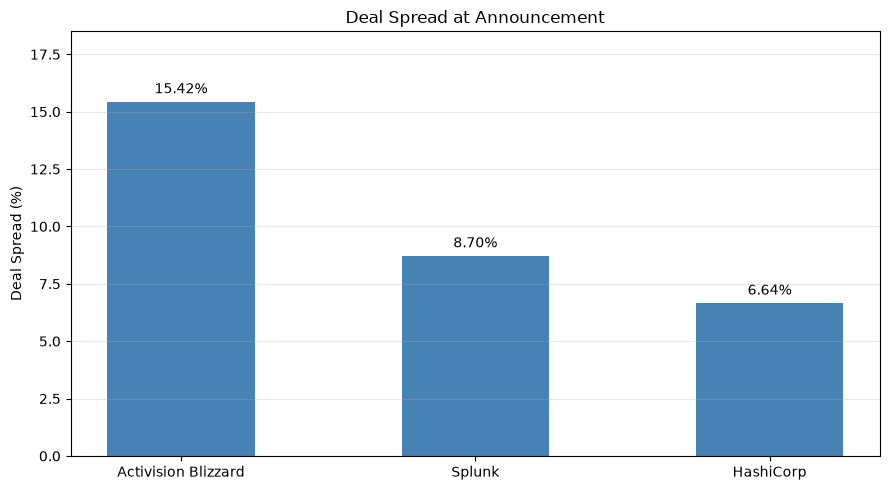

In [9]:
# Visualise deal spreads

plt.figure(figsize=(9, 5))

bars = plt.bar(
    deals["Target"],
    deals["Spread_Pct"],
    color="steelblue",
    width=0.5
)

plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.title("Deal Spread at Announcement")
plt.ylabel("Deal Spread (%)")
plt.ylim(0, deals["Spread_Pct"].max() * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

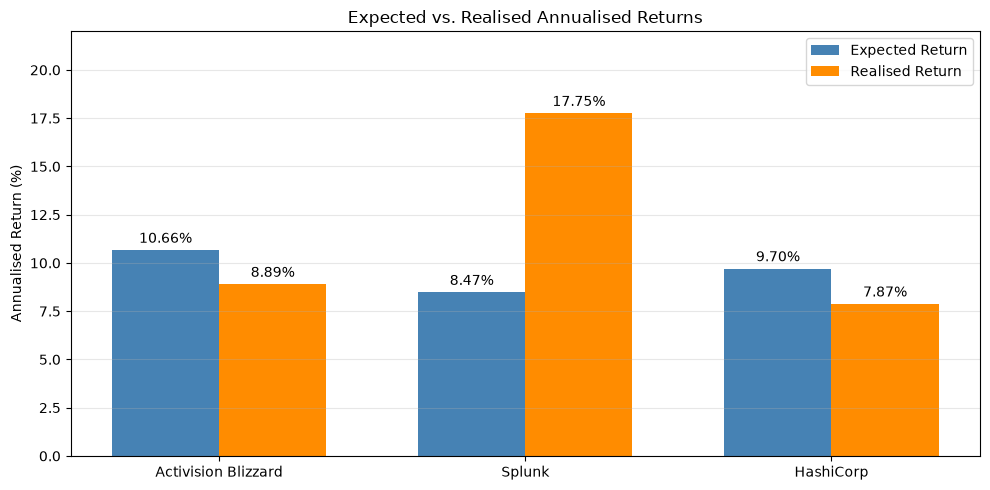

In [10]:
# Compare expected and realised annualised returns

x = np.arange(len(deals))
width = 0.35

plt.figure(figsize=(10, 5))

bars1 = plt.bar(
    x - width/2,
    deals["Expected_Annualised_Return"],
    width,
    label="Expected Return",
    color="steelblue"
)

bars2 = plt.bar(
    x + width/2,
    deals["Realised_Annualised_Return"],
    width,
    label="Realised Return",
    color="darkorange"
)

plt.bar_label(bars1, fmt="%.2f%%", padding=3)
plt.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.xticks(x, deals["Target"])
plt.title("Expected vs. Realised Annualised Returns")
plt.ylabel("Annualised Return (%)")
plt.ylim(0, 22)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

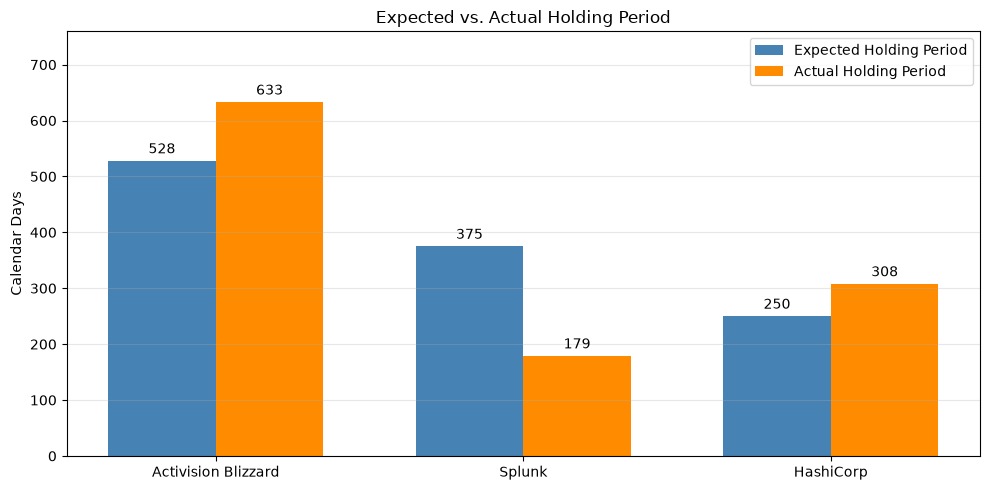

In [11]:
# Compare expected and actual holding periods

x = np.arange(len(deals))
width = 0.35

plt.figure(figsize=(10, 5))

bars1 = plt.bar(
    x - width/2,
    deals["Expected_Days"],
    width,
    label="Expected Holding Period",
    color="steelblue"
)

bars2 = plt.bar(
    x + width/2,
    deals["Actual_Days"],
    width,
    label="Actual Holding Period",
    color="darkorange"
)

plt.bar_label(bars1, fmt="%d", padding=3)
plt.bar_label(bars2, fmt="%d", padding=3)

plt.xticks(x, deals["Target"])
plt.title("Expected vs. Actual Holding Period")
plt.ylabel("Calendar Days")
plt.ylim(0, deals[["Expected_Days", "Actual_Days"]].max().max() * 1.2)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Stretch Task – Failed Merger 

In [17]:
# Import historical iRobot stock prices from Investing.com

failed_prices = pd.read_csv("iRobot Stock Price History.csv")

# Convert dates and rename the closing price column

failed_prices["Date"] = pd.to_datetime(
    failed_prices["Date"],
    format="%m/%d/%Y"
)

failed_prices = failed_prices.rename(
    columns={"Price": "Close"}
)

# Select the merger arbitrage holding period

failed_prices = failed_prices[
    (failed_prices["Date"] >= "2022-08-05") &
    (failed_prices["Date"] <= "2024-01-29")
].copy()

# Sort observations chronologically

failed_prices = failed_prices.sort_values("Date")
failed_prices = failed_prices.reset_index(drop=True)

print(f"Number of observations: {len(failed_prices)}")

display(failed_prices.head())
display(failed_prices.tail())


Number of observations: 372


,Date,Close,Open,High,Low,Vol.,Change %
0,2022-08-05,59.54,59.70,60.09,59.45,14.81M,19.10%
1,2022-08-08,59.62,59.53,59.66,59.25,4.41M,0.13%
2,2022-08-09,59.64,59.50,59.66,59.44,1.53M,0.03%
3,2022-08-10,59.60,59.62,59.78,59.42,2.28M,-0.07%
4,2022-08-11,59.87,59.63,60.00,59.50,2.00M,0.45%


,Date,Close,Open,High,Low,Vol.,Change %
367,2024-01-23,18.48,17.38,19.68,16.90,6.68M,6.33%
368,2024-01-24,17.61,18.85,19.45,17.55,2.97M,-4.71%
369,2024-01-25,17.58,17.64,17.94,16.39,2.81M,-0.17%
370,2024-01-26,16.99,17.35,17.37,16.81,1.33M,-3.36%
371,2024-01-29,15.50,14.07,16.25,13.80,18.32M,-8.77%


In [18]:
# Calculate the initial deal spread and realised loss

initial_offer = 61.00
revised_offer = 51.75

entry_price = failed_prices["Close"].iloc[0]
exit_price = failed_prices["Close"].iloc[-1]

entry_date = failed_prices["Date"].iloc[0]
exit_date = failed_prices["Date"].iloc[-1]

holding_days = (exit_date - entry_date).days

initial_spread = (
    (initial_offer - entry_price) / entry_price
) * 100

realised_return = (
    (exit_price - entry_price) / entry_price
) * 100

realised_annualised = (
    realised_return * 365 / holding_days
)

failed_summary = pd.DataFrame({
    "Metric": [
        "Initial offer price ($)",
        "Revised offer price ($)",
        "Entry price ($)",
        "Exit price ($)",
        "Initial deal spread (%)",
        "Actual holding period (days)",
        "Realised return (%)",
        "Realised annualised return (%)"
    ],
    "Value": [
        initial_offer,
        revised_offer,
        entry_price,
        exit_price,
        initial_spread,
        holding_days,
        realised_return,
        realised_annualised
    ]
})

display(failed_summary.round(2))

,Metric,Value
0,Initial offer price ($),61.00
1,Revised offer price ($),51.75
2,Entry price ($),59.54
3,Exit price ($),15.50
4,Initial deal spread (%),2.45
5,Actual holding period (days),542.00
6,Realised return (%),-73.97
7,Realised annualised return (%),-49.81


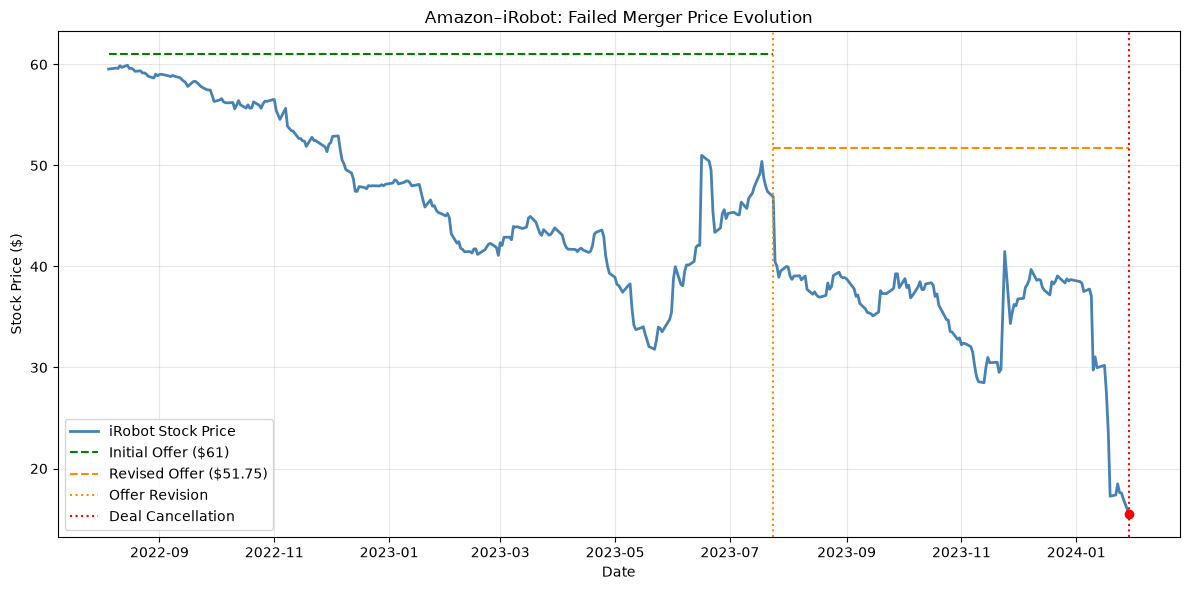

In [19]:
# Visualise iRobot stock prices during the merger process

revision_date = pd.Timestamp("2023-07-24")
cancellation_date = pd.Timestamp("2024-01-29")

plt.figure(figsize=(12, 6))

plt.plot(
    failed_prices["Date"],
    failed_prices["Close"],
    label="iRobot Stock Price",
    color="steelblue",
    linewidth=2
)

# Initial and revised offer prices

plt.hlines(
    initial_offer,
    entry_date,
    revision_date,
    colors="green",
    linestyles="--",
    label="Initial Offer ($61)"
)

plt.hlines(
    revised_offer,
    revision_date,
    cancellation_date,
    colors="darkorange",
    linestyles="--",
    label="Revised Offer ($51.75)"
)

# Mark important merger events

plt.axvline(
    revision_date,
    color="darkorange",
    linestyle=":",
    label="Offer Revision"
)

plt.axvline(
    cancellation_date,
    color="red",
    linestyle=":",
    label="Deal Cancellation"
)

plt.scatter(
    exit_date,
    exit_price,
    color="red",
    zorder=5
)

plt.title("Amazon–iRobot: Failed Merger Price Evolution")
plt.xlabel("Date")
plt.ylabel("Stock Price ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Maximum Drawdown: -74.13%


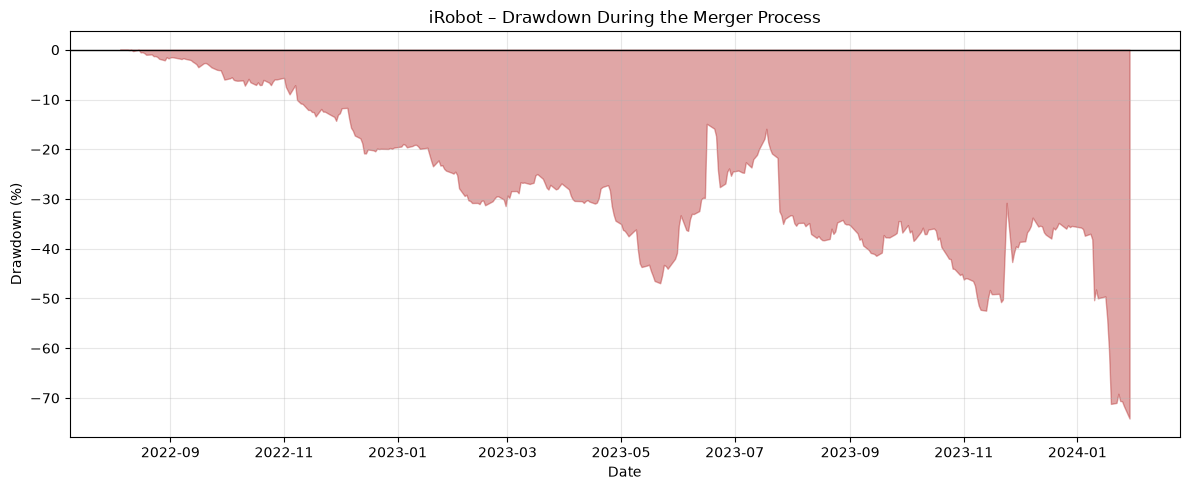

In [20]:
# Calculate maximum drawdown for the failed merger

failed_prices["Running_Max"] = (
    failed_prices["Close"].cummax()
)

failed_prices["Drawdown"] = (
    failed_prices["Close"] /
    failed_prices["Running_Max"] - 1
)

max_drawdown = failed_prices["Drawdown"].min() * 100

print(f"Maximum Drawdown: {max_drawdown:.2f}%")

# Visualise the drawdown

plt.figure(figsize=(12, 5))

plt.fill_between(
    failed_prices["Date"],
    failed_prices["Drawdown"] * 100,
    0,
    color="firebrick",
    alpha=0.4
)

plt.axhline(0, color="black", linewidth=1)

plt.title("iRobot – Drawdown During the Merger Process")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# Import historical prices for completed mergers

files = {
    "ATVI": "Activision Blizzard Stock Price History.csv",
    "SPLK": "Splunk Stock Price History.csv",
    "HCP": "Hashicorp Stock Price History.csv"
}

successful_prices = {}

for ticker, filename in files.items():

    data = pd.read_csv(filename)

    data["Date"] = pd.to_datetime(
        data["Date"], format="%m/%d/%Y"
    )

    data = data.rename(columns={"Price": "Close"})

    data = data[["Date", "Close"]]

    data = data.sort_values("Date").reset_index(drop=True)

    successful_prices[ticker] = data

    print(f"{ticker}: {len(data)} observations")
    print(f"Start: {data['Date'].min().date()}")
    print(f"End: {data['Date'].max().date()}")
    print()

ATVI: 447 observations
Start: 2022-01-03
End: 2023-10-12

SPLK: 135 observations
Start: 2023-09-01
End: 2024-03-15

HCP: 228 observations
Start: 2024-04-01
End: 2025-02-26



In [22]:
# Prepare price series for completed mergers

deal_series = {}

for _, row in deals.iterrows():

    ticker = row["Ticker"]
    start = row["Entry_Date"]
    end = row["Actual_Close"]

    data = successful_prices[ticker].copy()

    data = data[
        (data["Date"] >= start) &
        (data["Date"] < end)
    ].copy()

    # Check entry price consistency
    actual_entry = data["Close"].iloc[0]

    print(f"{ticker}")
    print(f"Original entry price: {row['Entry_Price']:.2f}")
    print(f"CSV entry price: {actual_entry:.2f}")

    # Add final cash payment on the closing date
    final_payment = pd.DataFrame({
        "Date": [end],
        "Close": [row["Final_Cash_Payment"]]
    })

    data = pd.concat(
        [data, final_payment],
        ignore_index=True
    )

    data = data.sort_values("Date").set_index("Date")

    # Normalise investment value
    deal_series[ticker] = data["Close"] / actual_entry

    print(f"Final investment value: {deal_series[ticker].iloc[-1]:.4f}")
    print()

ATVI
Original entry price: 82.31
CSV entry price: 82.31
Final investment value: 1.1542

SPLK
Original entry price: 144.43
CSV entry price: 144.43
Final investment value: 1.0870

HCP
Original entry price: 32.82
CSV entry price: 32.82
Final investment value: 1.0664



In [23]:
# Add the failed merger to the investment series

deal_series["IRBT"] = (
    failed_prices.set_index("Date")["Close"] / entry_price
)

# Create a common calendar for all merger investments

calendar = pd.date_range(
    start=deals["Entry_Date"].min(),
    end=deals["Actual_Close"].max(),
    freq="D"
)

# Align all investment series

portfolio_data = pd.DataFrame(index=calendar)

for ticker, series in deal_series.items():

    portfolio_data[ticker] = (
        series.reindex(calendar)
        .ffill()
        .fillna(1.0)
    )

portfolio_data.index.name = "Date"

display(portfolio_data.head())
display(portfolio_data.tail())

,ATVI,SPLK,HCP,IRBT
Date,,,,
2022-01-18,1.000000,1.0,1.0,1.0
2022-01-19,0.998056,1.0,1.0,1.0
2022-01-20,0.993318,1.0,1.0,1.0
2022-01-21,0.988337,1.0,1.0,1.0
2022-01-22,0.988337,1.0,1.0,1.0


,ATVI,SPLK,HCP,IRBT
Date,,,,
2025-02-23,1.154173,1.087032,1.051188,0.260329
2025-02-24,1.154173,1.087032,1.049360,0.260329
2025-02-25,1.154173,1.087032,1.060634,0.260329
2025-02-26,1.154173,1.087032,1.059720,0.260329
2025-02-27,1.154173,1.087032,1.066423,0.260329


In [24]:
# Construct two equally allocated merger portfolios

initial_capital = 10000

# Portfolio A: completed mergers only

portfolio_data["Portfolio_A"] = (
    portfolio_data[["ATVI", "SPLK", "HCP"]].mean(axis=1)
    * initial_capital
)

# Portfolio B: completed and failed mergers

portfolio_data["Portfolio_B"] = (
    portfolio_data[["ATVI", "SPLK", "HCP", "IRBT"]].mean(axis=1)
    * initial_capital
)

# Display initial and final portfolio values

display(portfolio_data[[
    "Portfolio_A",
    "Portfolio_B"
]].iloc[[0, -1]].round(2))

,Portfolio_A,Portfolio_B
Date,,
2022-01-18,10000.00,10000.00
2025-02-27,11025.43,8919.89


,Portfolio,Final_Value,Total_Return_Pct,Maximum_Drawdown_Pct
0,Portfolio_A,11025.43,10.25,-4.83
1,Portfolio_B,8919.89,-10.80,-13.10


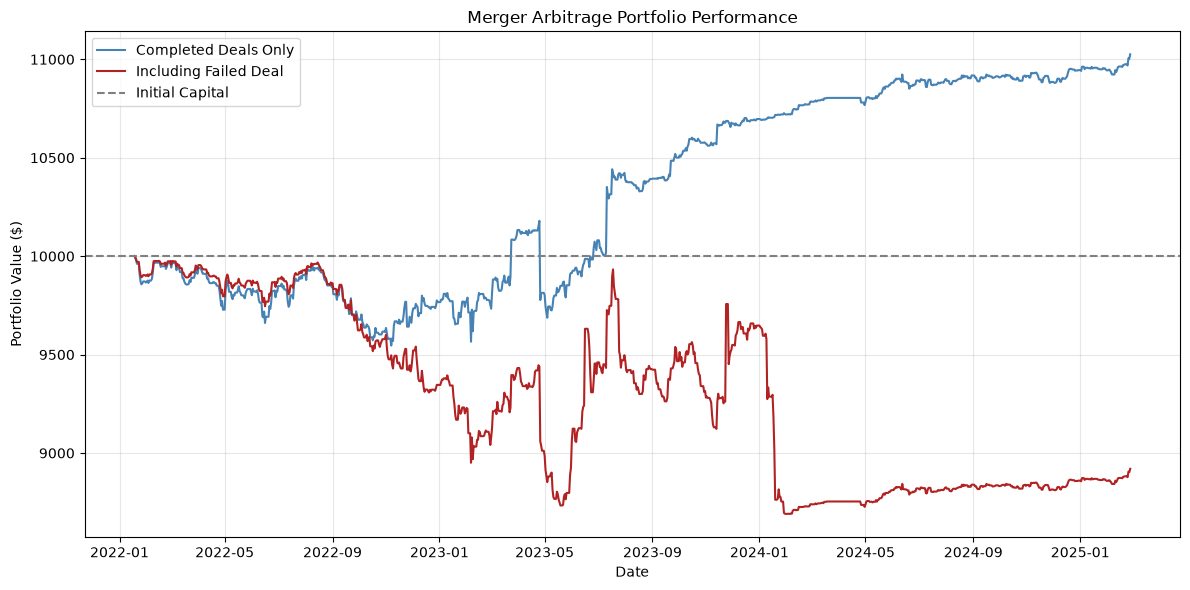

In [25]:
# Calculate portfolio returns and maximum drawdowns

portfolio_results = []

for name in ["Portfolio_A", "Portfolio_B"]:

    equity = portfolio_data[name]

    total_return = (
        equity.iloc[-1] / equity.iloc[0] - 1
    ) * 100

    drawdown = equity / equity.cummax() - 1

    portfolio_results.append({
        "Portfolio": name,
        "Final_Value": equity.iloc[-1],
        "Total_Return_Pct": total_return,
        "Maximum_Drawdown_Pct": drawdown.min() * 100
    })

portfolio_results = pd.DataFrame(portfolio_results)

display(portfolio_results.round(2))

# Compare portfolio equity curves

plt.figure(figsize=(12, 6))

plt.plot(
    portfolio_data.index,
    portfolio_data["Portfolio_A"],
    label="Completed Deals Only",
    color="steelblue"
)

plt.plot(
    portfolio_data.index,
    portfolio_data["Portfolio_B"],
    label="Including Failed Deal",
    color="firebrick"
)

plt.axhline(
    initial_capital,
    color="gray",
    linestyle="--",
    label="Initial Capital"
)

plt.title("Merger Arbitrage Portfolio Performance")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Data Sources

- Investing.com – Historical daily stock prices
- SEC EDGAR – Merger filings
- Corporate acquisition announcements